In [38]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
from xgboost import XGBRegressor

#### 1. Training/Validation data preparation

In [39]:
data = pl.read_csv("exp_data.csv").with_row_index()

In [41]:
tie_lines_train = data.sample(fraction=0.8, with_replacement=False, seed=42).sort("index")
tie_lines_validate = data.filter(~data["index"].is_in(tie_lines_train["index"]))
tie_lines_train = tie_lines_train.drop(["index"])
tie_lines_validate = tie_lines_validate.drop(["index"])

In [42]:
X_train = tie_lines_train.select(['Temperature (K)', 'Type Alcohol', 'FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 
                                  'ACID_F', 'WATER_F','MW_FAME/FAEE', 'MW_Oil', 'MW_DAG', 'MW_MAG', 'MW_FA']).to_numpy()
y_train = tie_lines_train.select(['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 
                                  'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']).to_numpy()

In [43]:
X_val= tie_lines_validate.select(['Temperature (K)', 'Type Alcohol', 'FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 
                                  'ACID_F', 'WATER_F','MW_FAME/FAEE', 'MW_Oil', 'MW_DAG', 'MW_MAG', 'MW_FA']).to_numpy()
y_val = tie_lines_validate.select(['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 
                                  'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']).to_numpy()

In [44]:
X_total = data.select(['Temperature (K)', 'Type Alcohol', 'FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 
                                  'ACID_F', 'WATER_F','MW_FAME/FAEE', 'MW_Oil', 'MW_DAG', 'MW_MAG', 'MW_FA']).to_numpy()
y_total = data.select(['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 
                                  'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']).to_numpy()

#### 2. Metric evaluation

In [45]:
def metrics(y_train, y_val, y_total, y_pred_train, y_pred_val, y_pred_total):
    
    r2_train = r2_score(y_train, y_pred_train)
    r2_val = r2_score(y_val, y_pred_val)
    r2_total = r2_score(y_total, y_pred_total)

    RMSE_train = root_mean_squared_error(y_train, y_pred_train)
    RMSE_val = root_mean_squared_error(y_val, y_pred_val)
    RMSE_total = root_mean_squared_error(y_total, y_pred_total)
    
    print(f"Training: R2: {round(r2_train, 4)} \n RMSE: {round(RMSE_train, 4)}")
    print(f"Validate: R2: {round(r2_val, 4)} \n RMSE: {round(RMSE_val, 4)}")
    print(f"Total: R2: {round(r2_total, 4)} \n RMSE: {round(RMSE_total, 4)}")
    

In [46]:
def graph_corr(y_true, y_pred, title, save):
    sns.set_theme(rc={'figure.figsize':(15,8)})
    sns.set_style("whitegrid")

    sns.lineplot(x = [0,1], y=[0,1], color = "black")
    sns.scatterplot(x = y_true[:, 0], y = y_pred[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")
    sns.scatterplot(x = y_true[:, 8], y = y_pred[:, 8], facecolor = "none", edgecolor = "red")

    sns.scatterplot(x = y_true[:, 1], y = y_pred[:, 1], facecolor = "none", edgecolor = "blue", label = "Glycerol")
    sns.scatterplot(x = y_true[:, 9], y = y_pred[:, 9], facecolor = "none", edgecolor = "blue")

    sns.scatterplot(x = y_true[:, 2], y = y_pred[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")
    sns.scatterplot(x = y_true[:, 10], y = y_pred[:, 10], facecolor = "none", edgecolor = "green")

    sns.scatterplot(x = y_true[:, 3], y = y_pred[:, 3], facecolor = "none", edgecolor = "orange", label = "Oil")
    sns.scatterplot(x = y_true[:, 11], y = y_pred[:, 11], facecolor = "none", edgecolor = "orange")

    sns.scatterplot(x = y_true[:, 4], y = y_pred[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")
    sns.scatterplot(x = y_true[:, 12], y = y_pred[:, 12], facecolor = "none", edgecolor = "goldenrod")

    sns.scatterplot(x = y_true[:, 5], y = y_pred[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")
    sns.scatterplot(x = y_true[:, 13], y = y_pred[:, 13], facecolor = "none", edgecolor = "darkviolet")

    sns.scatterplot(x = y_true[:, 6], y = y_pred[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acid")
    sns.scatterplot(x = y_true[:, 14], y = y_pred[:, 14], facecolor = "none", edgecolor = "darkcyan")

    sns.scatterplot(x = y_true[:, 7], y = y_pred[:, 7], facecolor = "none", edgecolor = "magenta", label = "Water")
    sns.scatterplot(x = y_true[:, 15], y = y_pred[:, 15], facecolor = "none", edgecolor = "magenta")

    plt.xlabel("Experimental composition (%w)", fontsize=16)
    plt.ylabel("Calculated composition (%w)", fontsize=16)
    plt.legend(loc = "upper left")
    sns.set_context("talk", font_scale=2)
    plt.xticks(fontsize=15)
    plt.yticks(fontsize=15)
    plt.title(title)
    if save == True:
        plt.savefig('UNIFACD_CORR_new.png', dpi=1000, bbox_inches='tight')
        
    plt.show()
    

#### 3. Models

##### 3.1 Random Forest

In [47]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [48]:
y_pred_train = rf.predict(X_train)
y_pred_val = rf.predict(X_val)
y_pred_total = rf.predict(X_total)

In [49]:
metrics(y_train, y_val, y_total, y_pred_train, y_pred_val, y_pred_total)

Training: R2: 0.9868 
 RMSE: 0.0058
Validate: R2: 0.9016 
 RMSE: 0.0147
Total: R2: 0.9716 
 RMSE: 0.0084


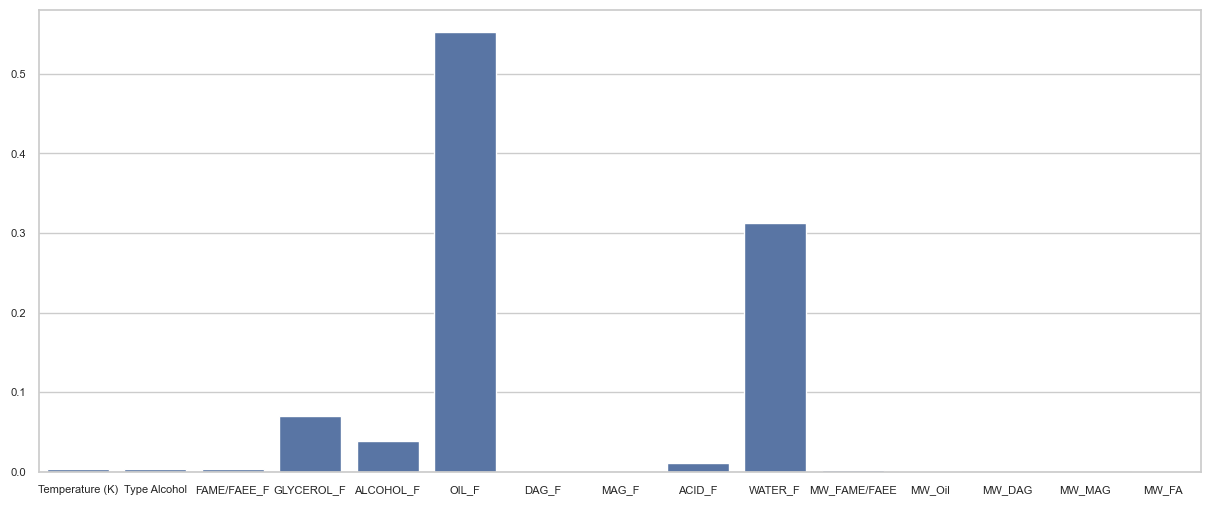

In [50]:
sns.set_theme(rc={'figure.figsize':(15,6)})
sns.set_style("whitegrid")
sns.barplot(x = ['Temperature (K)', 'Type Alcohol', 'FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 
                                  'ACID_F', 'WATER_F','MW_FAME/FAEE', 'MW_Oil', 'MW_DAG', 'MW_MAG', 'MW_FA'], y=rf.feature_importances_)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.show()

In [52]:
# Save the model
#with open("random_forest_model.pkl", "wb") as f:
    #pickle.dump(rf, f)

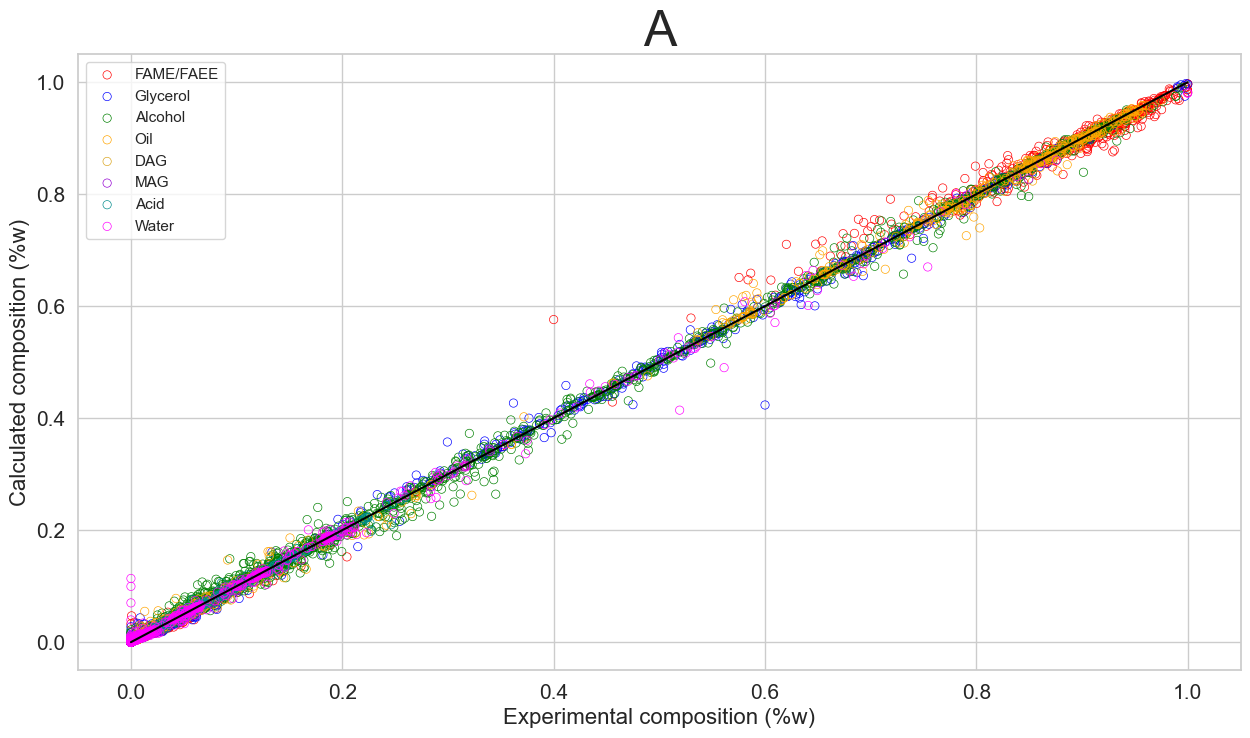

In [53]:
graph_corr(y_train, y_pred_train, "A", False)

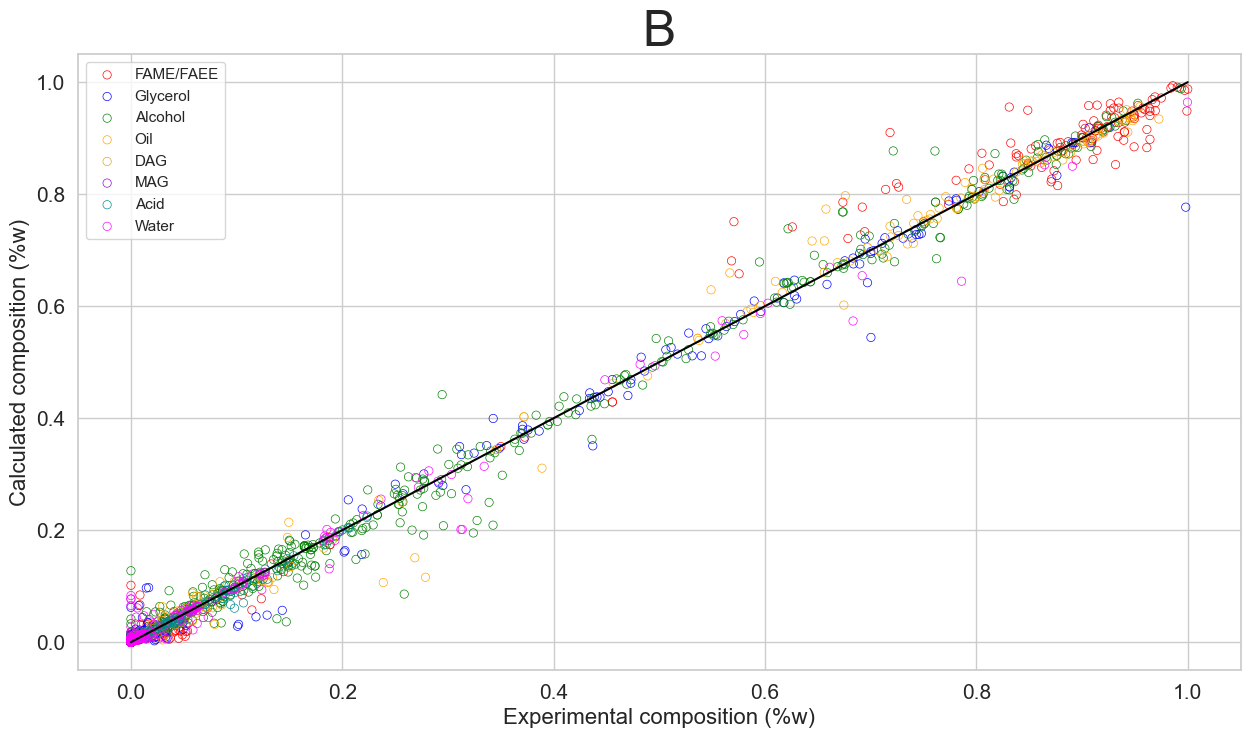

In [54]:
graph_corr(y_val, y_pred_val, "B", False)

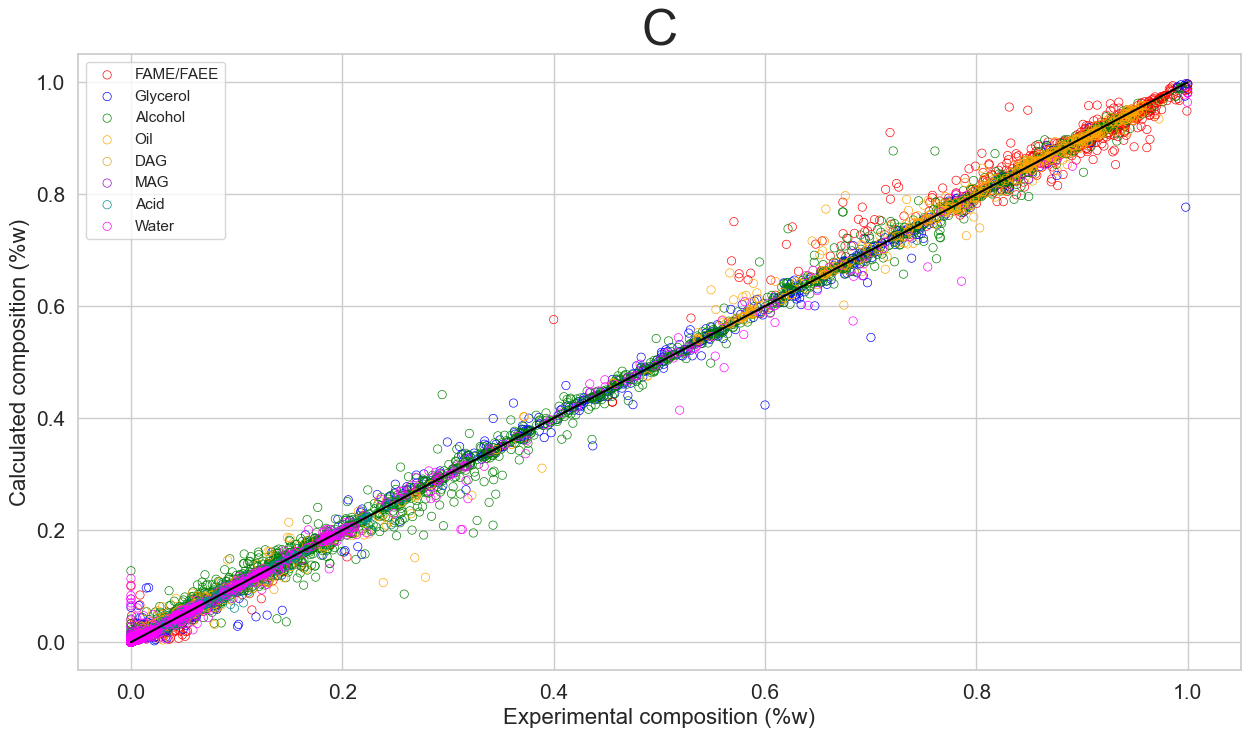

In [55]:
graph_corr(y_total, y_pred_total, "C", False)

##### 3.2 XGBoost Regressor

In [56]:
xgb_regressor = XGBRegressor()
xgb_regressor.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [57]:
y_pred_train = xgb_regressor.predict(X_train)
y_pred_val = xgb_regressor.predict(X_val)
y_pred_total = xgb_regressor.predict(X_total)

In [58]:
metrics(y_train, y_val, y_total, y_pred_train, y_pred_val, y_pred_total)

Training: R2: 0.9991 
 RMSE: 0.001
Validate: R2: 0.9313 
 RMSE: 0.0142
Total: R2: 0.9863 
 RMSE: 0.0064


In [ ]:
# Save the model
#with open("xgb_regressor_model.pkl", "wb") as f:
    #pickle.dump(xgb_regressor, f)

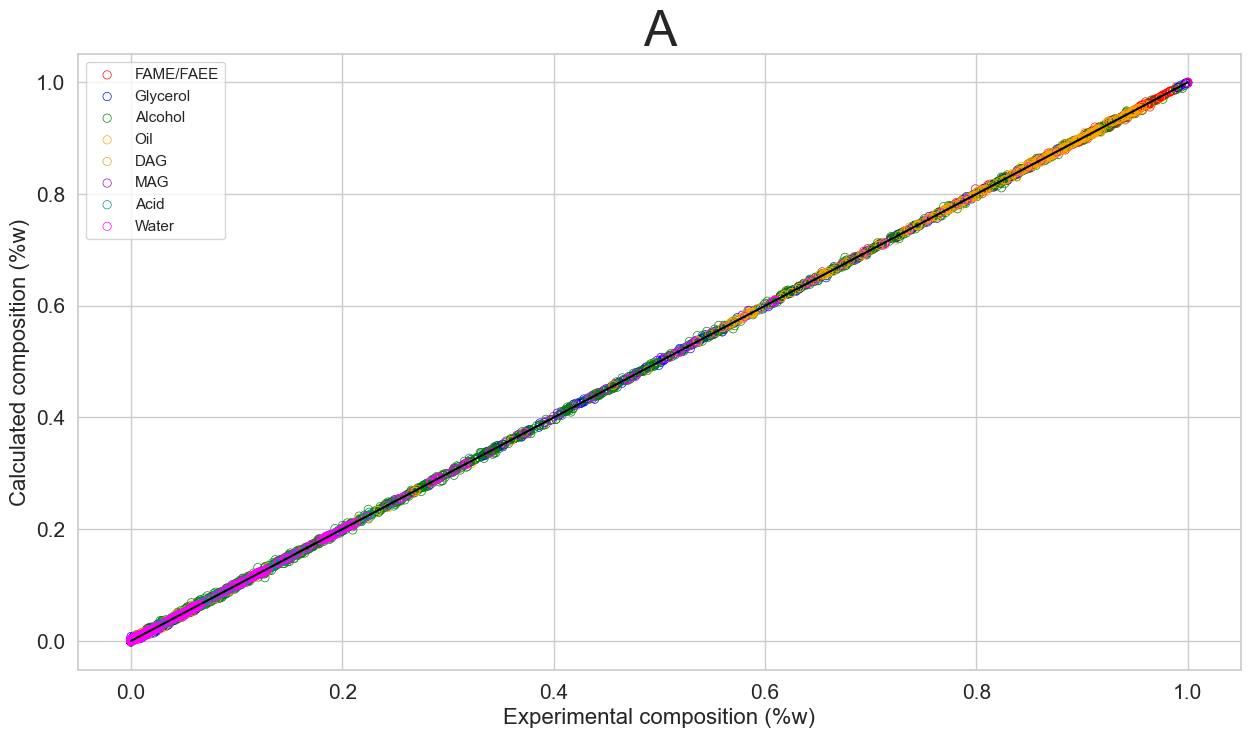

In [60]:
graph_corr(y_train, y_pred_train, "A", False)

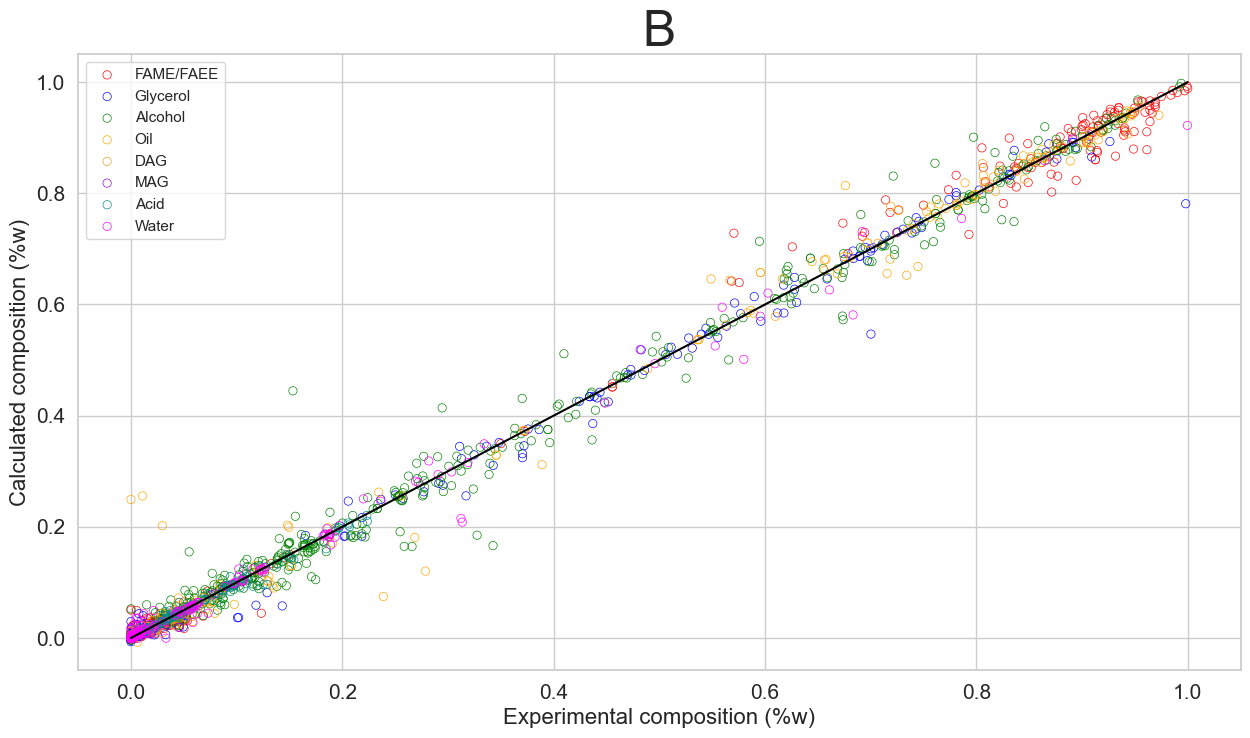

In [61]:
graph_corr(y_val, y_pred_val, "B", False)

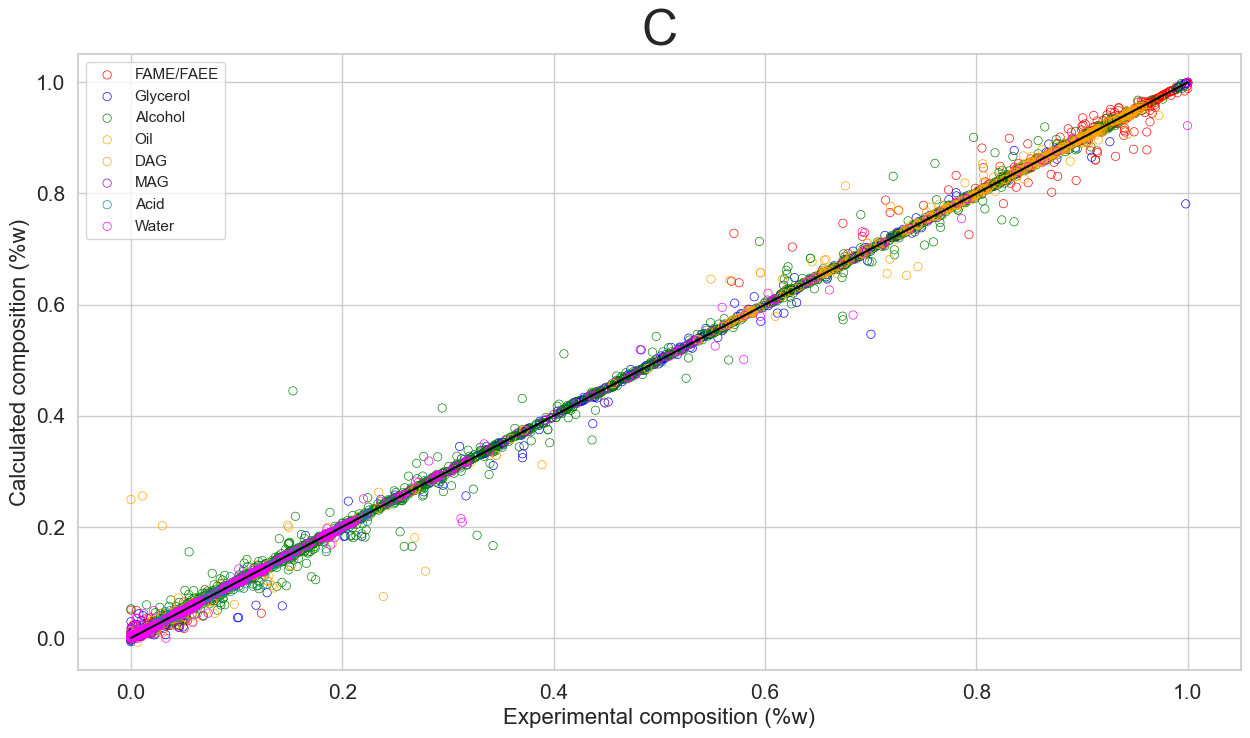

In [62]:
graph_corr(y_total, y_pred_total, "C", False)

##### 3.3 MLP

In [72]:
mlp_regressor = MLPRegressor(random_state=42, max_iter=2000, hidden_layer_sizes=(100, 200, 100, 200))
mlp_regressor.fit(X_train, y_train)

MLPRegressor(hidden_layer_sizes=(100, 200, 100, 200), max_iter=2000,
             random_state=42)

In [73]:
y_pred_train = mlp_regressor.predict(X_train)
y_pred_val = mlp_regressor.predict(X_val)
y_pred_total = mlp_regressor.predict(X_total)

In [74]:
metrics(y_train, y_val, y_total, y_pred_train, y_pred_val, y_pred_total)

Training: R2: -31.1975 
 RMSE: 0.1192
Validate: R2: -29.8062 
 RMSE: 0.1263
Total: R2: -30.5482 
 RMSE: 0.1207


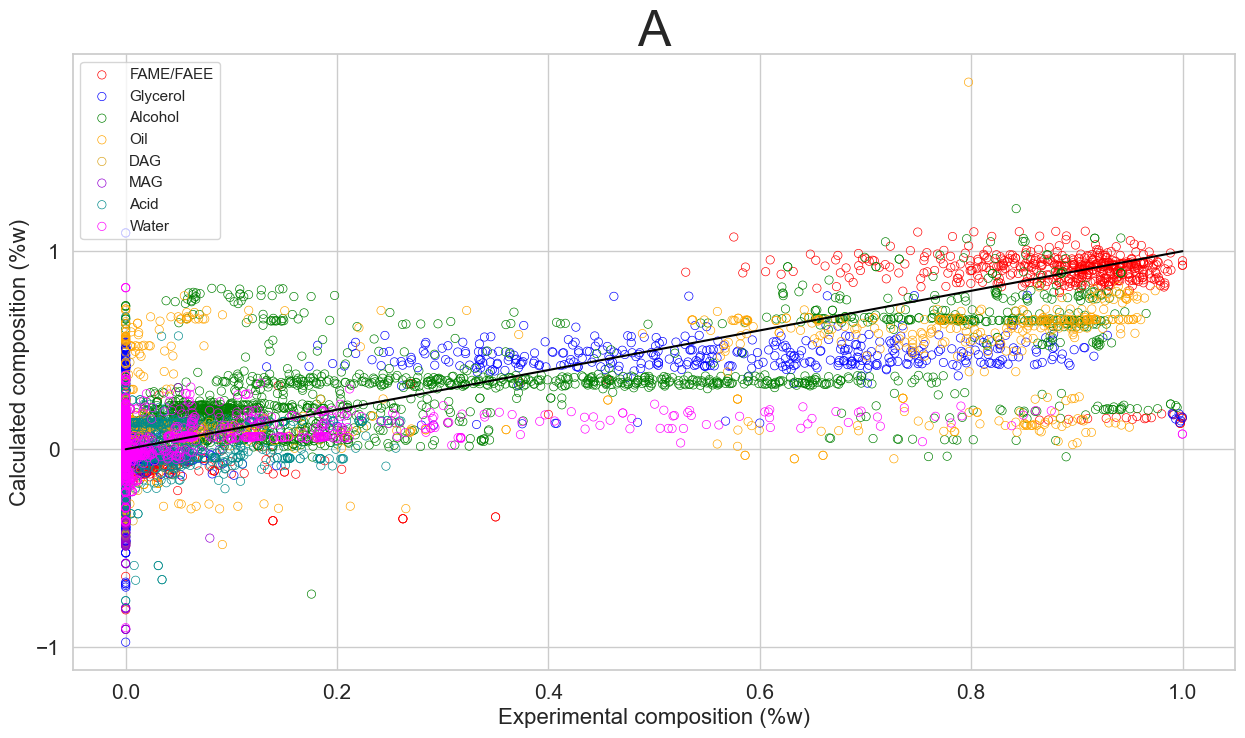

In [ ]:
graph_corr(y_train, y_pred_train, "A", False)

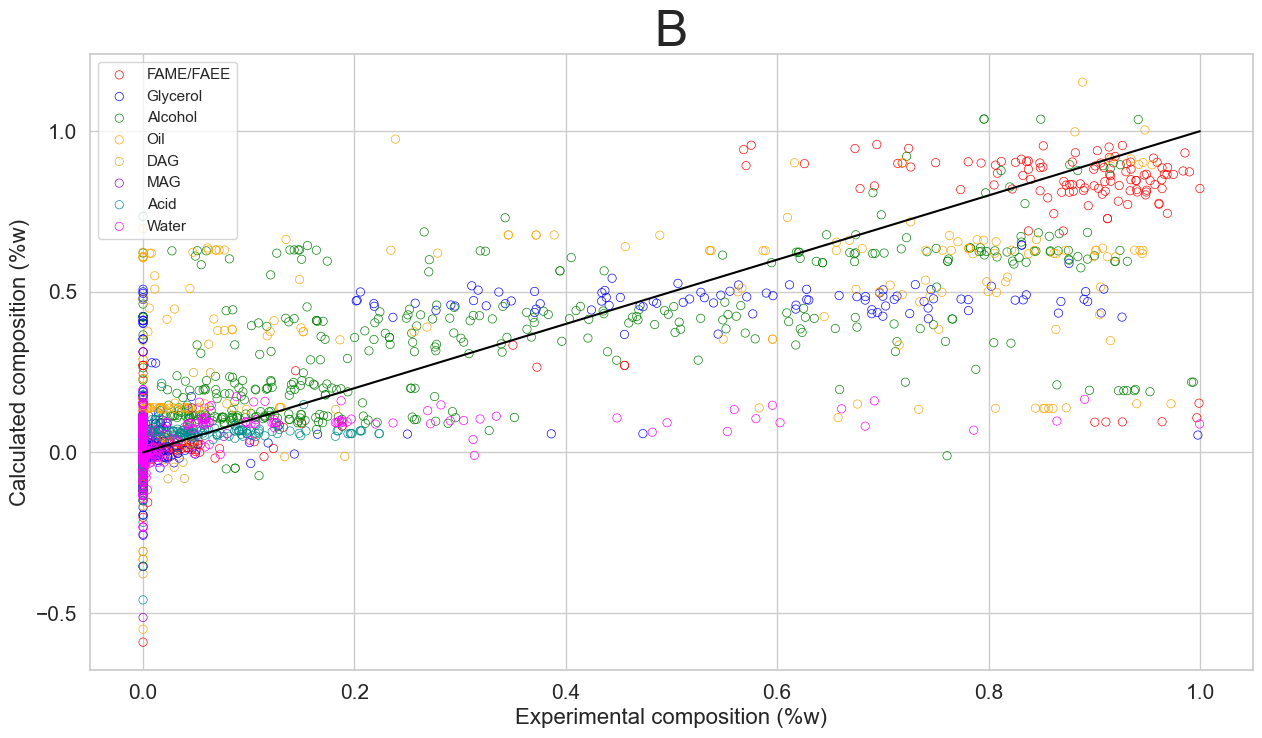

In [ ]:
graph_corr(y_val, y_pred_val, "B", False)

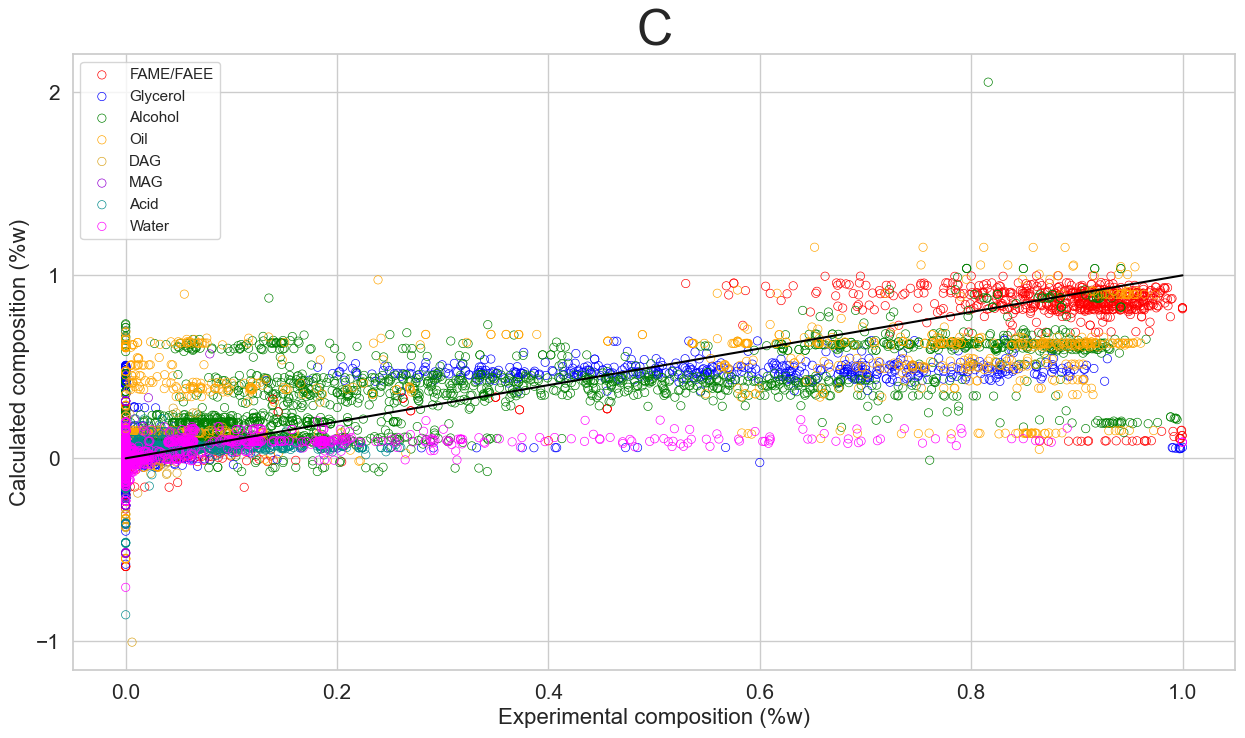

In [76]:
graph_corr(y_total, y_pred_total, "C", False)